In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
df = pd.read_csv(
    r"D:\Projects\zomato EDA\data\zomato.csv",
    encoding="utf-8",
    encoding_errors="ignore"
)
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
print(f"Shape of data : {df.shape}")
print(f"columns of data : {df.columns}")


Shape of data : (9551, 21)
columns of data : Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')


## 2. Understand the data

In [4]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [5]:
df.dtypes.to_frame()

,0
Restaurant ID,int64
Restaurant Name,object
Country Code,int64
City,object
Address,object
Locality,object
Locality Verbose,object
Longitude,float64
Latitude,float64
Cuisines,object


In [6]:
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [8]:
numerical_column = df.select_dtypes(include = "number").columns
numerical_column

Index(['Restaurant ID', 'Country Code', 'Longitude', 'Latitude',
       'Average Cost for two', 'Price range', 'Aggregate rating', 'Votes'],
      dtype='object')

In [9]:
catagorical_column = df.select_dtypes(include = "object").columns
catagorical_column

Index(['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose',
       'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery',
       'Is delivering now', 'Switch to order menu', 'Rating color',
       'Rating text'],
      dtype='object')

## 3. Data Quality assesment

In [10]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [11]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

In [12]:
# check y/n columns 
col = ["Has Table booking","Has Online delivery","Is delivering now","Switch to order menu"]
for c in col :
    print(f"{c} : {df[c].unique()}")

Has Table booking : ['Yes' 'No']
Has Online delivery : ['No' 'Yes']
Is delivering now : ['No' 'Yes']
Switch to order menu : ['No']


## 4. Univariate analysis

In [13]:
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


<Axes: xlabel='Aggregate rating', ylabel='Count'>

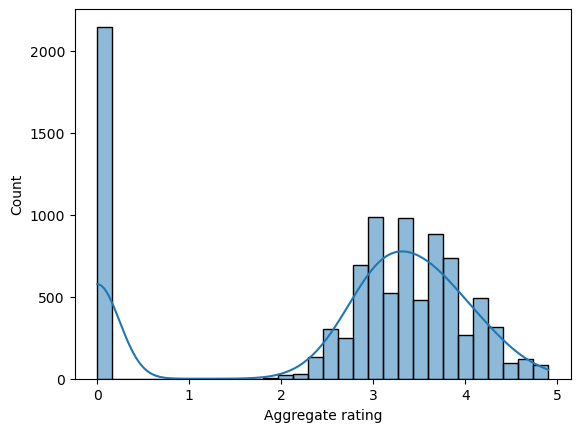

In [14]:
sns.histplot(df["Aggregate rating"],bins  = 30 ,kde = True)

In [15]:
df["Aggregate rating"].value_counts().head()

Aggregate rating
0.0    2148
3.2     522
3.1     519
3.4     498
3.3     483
Name: count, dtype: int64

Text(0, 0.5, 'Count')

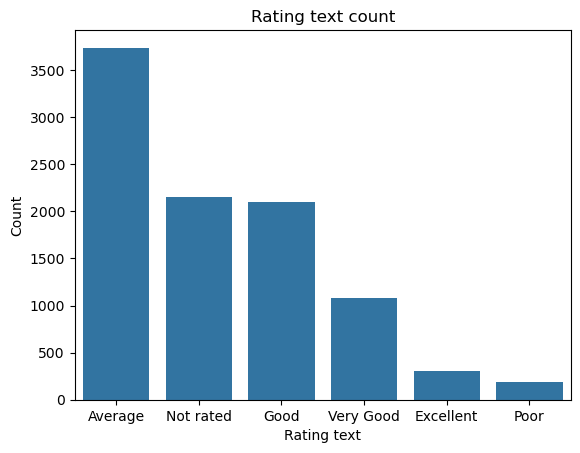

In [16]:
sns.barplot(df["Rating text"].value_counts())
plt.title("Rating text count")
plt.xlabel("Rating text")
plt.ylabel("Count")

In [17]:
 df[df["Rating text"] == "Not rated"][["Aggregate rating"]].value_counts()

# here we see that the "Not rated" rating text has 0 aggregate rating.
#  So we can replace the "Not rated" with "0" in the "Aggregate rating" column.

Aggregate rating
0.0                 2148
Name: count, dtype: int64

<Axes: ylabel='Votes'>

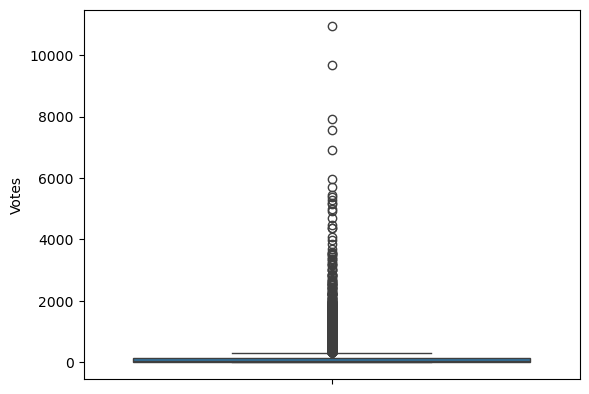

In [18]:
sns.boxplot(df["Votes"])

In [19]:
df[df["Votes"] == df["Votes"].max()]

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
728,51705,Toit,1,Bangalore,"298, Namma Metro Pillar 62, 100 Feet Road, Ind...",Indiranagar,"Indiranagar, Bangalore",77.640709,12.979166,"Italian, American, Pizza",...,Indian Rupees(Rs.),No,No,No,No,4,4.8,Dark Green,Excellent,10934


Text(0.5, 0, 'Average Cost for Two')

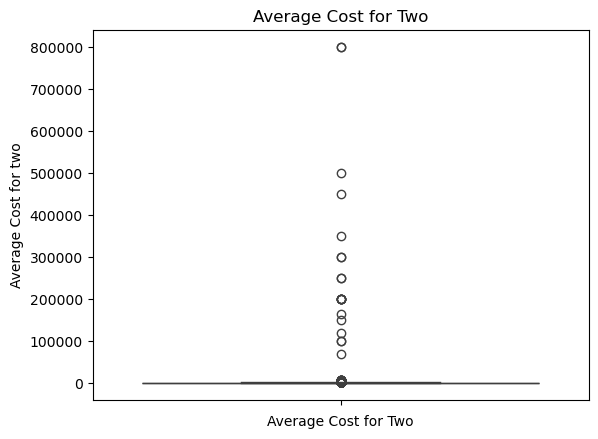

In [20]:
sns.boxplot(y=df["Average Cost for two"])
plt.title("Average Cost for Two")
plt.xlabel("Average Cost for Two")

In [21]:
price_count = df["Price range"].value_counts().sort_index()
price_count

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

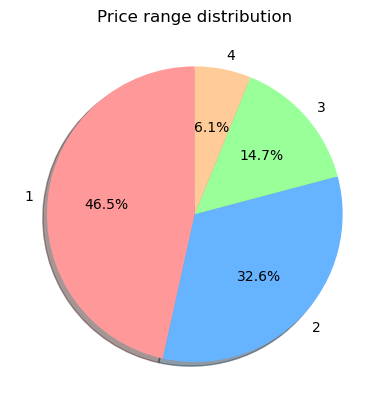

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

In [22]:
plt.pie(price_count,labels = price_count.index,autopct = "%1.1f%%" , shadow = True , startangle = 90 ,colors = ["#ff9999","#66b3ff","#99ff99","#ffcc99"])
plt.title("Price range distribution")   
plt.show()
plt.figure(figsize = (10,5))

In [23]:
top_stores =df["City"].value_counts().head(10)
top_stores

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64

<Axes: xlabel='City'>

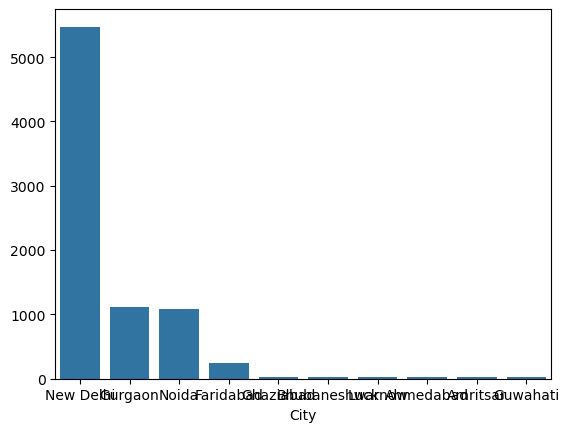

In [24]:
sns.barplot(x= top_stores.index , y = top_stores.values)

## 5. Bivariate analysis

In [25]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

#### Rating vs voting


In [26]:
df[["City",'Aggregate rating', 'Rating text','Votes']].sort_values(by='Votes', ascending=False).head(10)

,City,Aggregate rating,Rating text,Votes
728,Bangalore,4.8,Excellent,10934
735,Bangalore,4.7,Excellent,9667
3994,New Delhi,4.3,Very Good,7931
2412,Kolkata,4.3,Very Good,7574
739,Bangalore,4.6,Excellent,6907
2414,Kolkata,4.9,Excellent,5966
743,Bangalore,4.5,Excellent,5705
2307,Hyderabad,4.9,Excellent,5434
736,Bangalore,4.1,Very Good,5385
2411,Kolkata,4.2,Very Good,5288


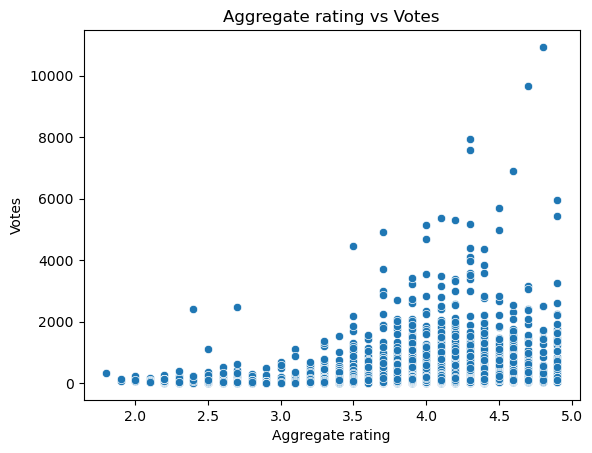

In [27]:
positive_rating = df[df["Aggregate rating"] > 0.0]
sns.scatterplot(x = positive_rating["Aggregate rating"] , y = positive_rating["Votes"])
plt.title("Aggregate rating vs Votes")
plt.show()

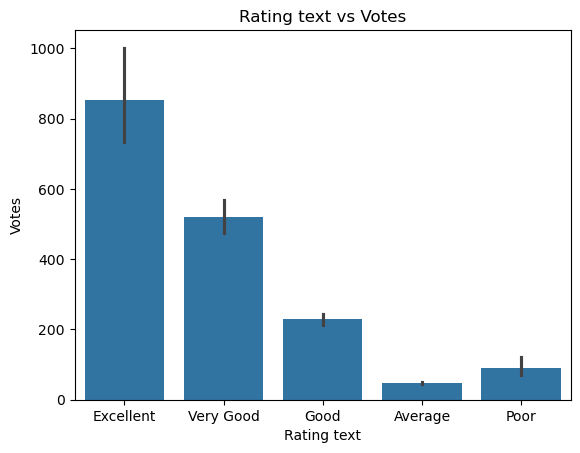

In [28]:
sns.barplot(x = positive_rating["Rating text"], y = positive_rating["Votes"])
plt.title("Rating text vs Votes")
plt.show()

In [29]:
correlation = positive_rating["Aggregate rating"].corr(positive_rating["Votes"])
correlation

np.float64(0.40901786341810925)

In [30]:
df["Price range"].value_counts().to_frame()

,count
Price range,
1,4444
2,3113
3,1408
4,586


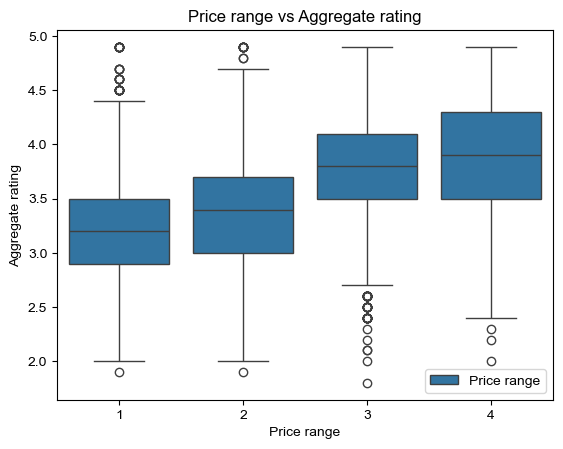

In [31]:
sns.boxplot(y = positive_rating["Aggregate rating"], x = positive_rating["Price range"] , label = "Price range")
plt.title("Price range vs Aggregate rating")
sns.set_theme(style="darkgrid")
plt.show()


In [32]:
avg_rating_by_price_range = positive_rating.groupby("Price range")["Aggregate rating"].median().to_frame()
avg_rating_by_price_range

,Aggregate rating
Price range,
1,3.2
2,3.4
3,3.8
4,3.9


In [33]:
df.dtypes

Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             object
Rating text              object
Votes                     int64
dtype: object

<Axes: >

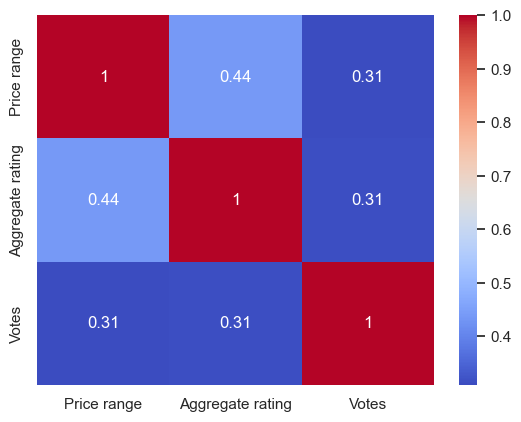

In [34]:
# correlation
corr = df[["Price range" ,"Aggregate rating" , "Votes"]].corr()    
sns.heatmap(corr, annot = True , cmap = "coolwarm")

## 6. Multivariate analysis

#### Pair plot analysis

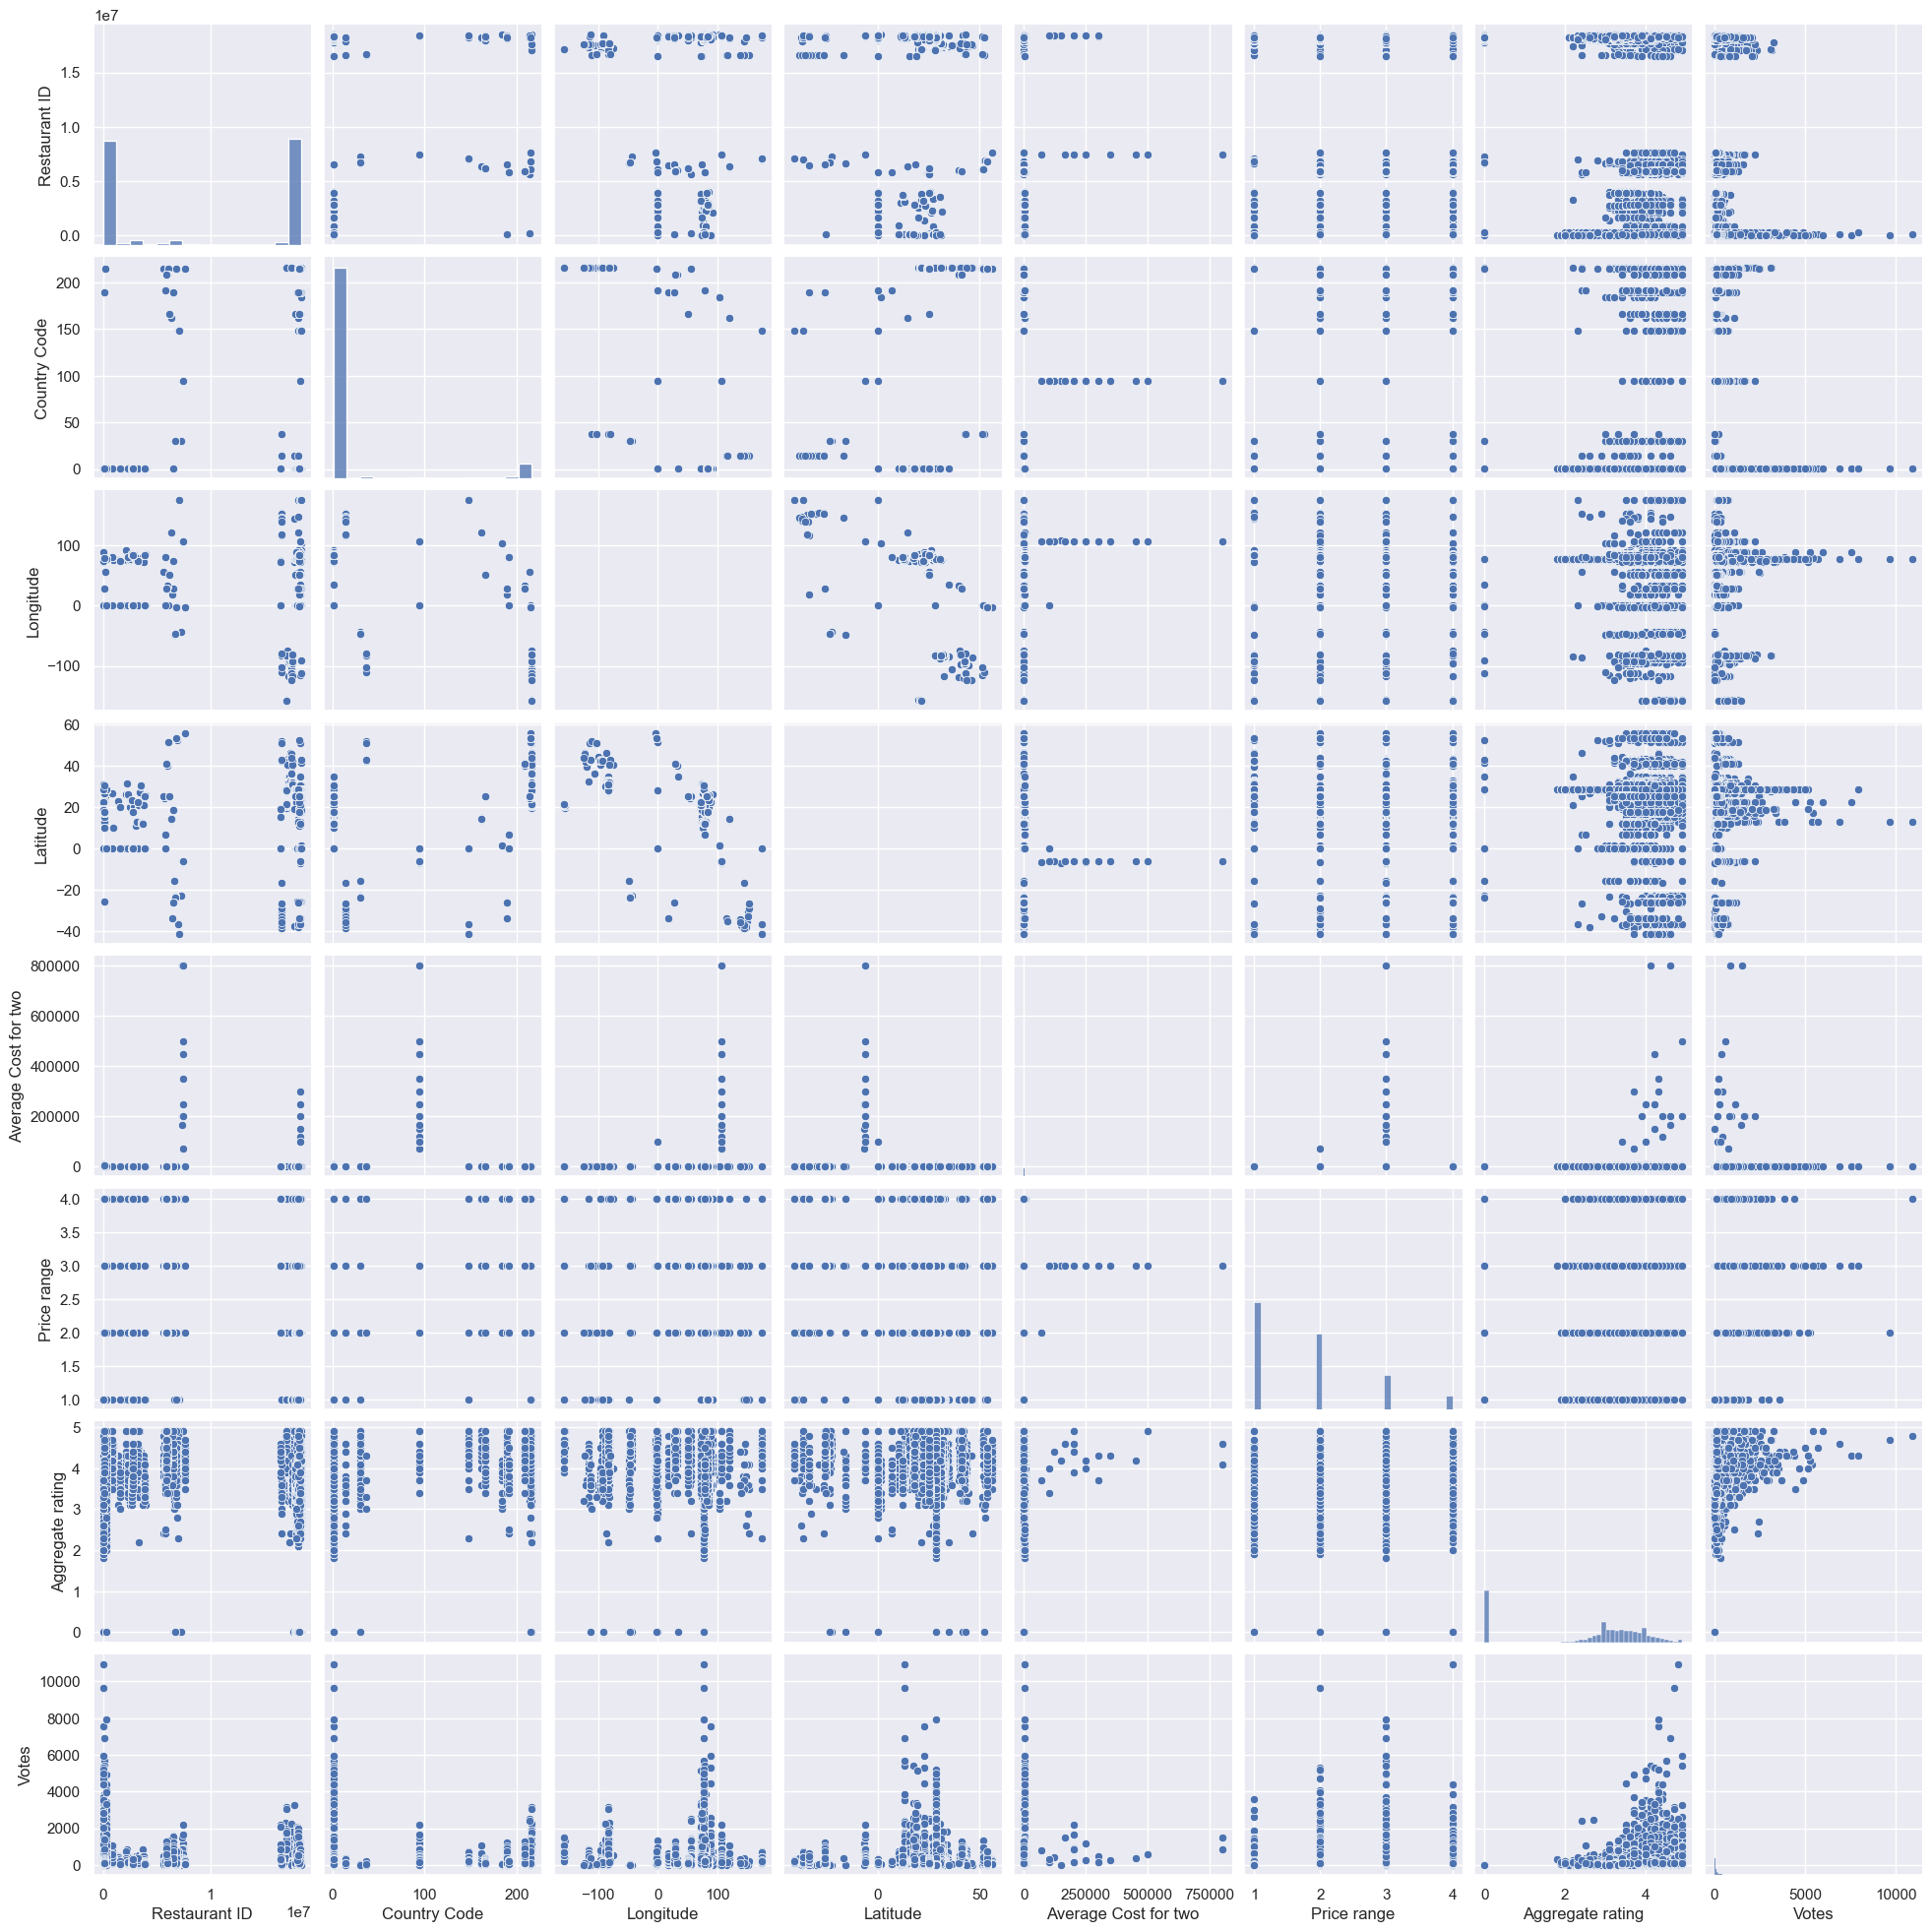

In [35]:
sns.pairplot(df[numerical_column])

<Axes: xlabel='Has Online delivery', ylabel='Aggregate rating'>

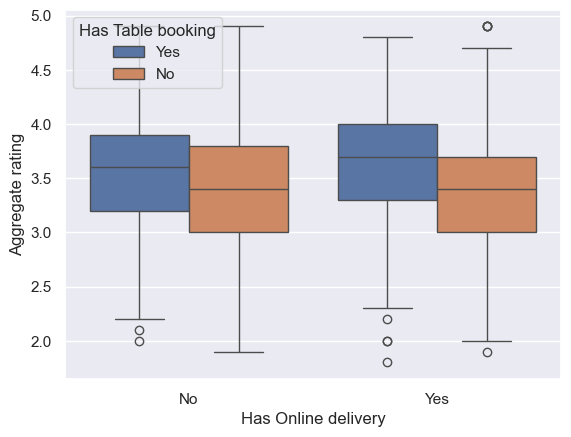

In [36]:
sns.boxplot( y = positive_rating["Aggregate rating"], x = positive_rating["Has Online delivery"] , hue = positive_rating["Has Table booking"])

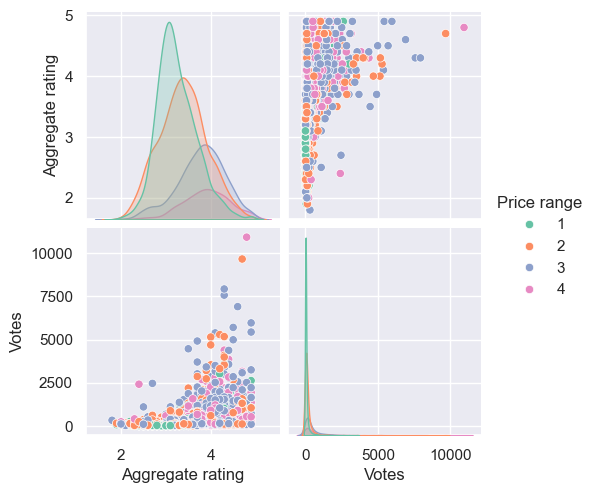

In [37]:
sns.pairplot(positive_rating[["Aggregate rating", "Votes" , "Price range"]], hue="Price range", palette="Set2")

In [38]:
# top 10 cites with hightest stores
top_cites = df["City"].value_counts().head()
top_cites

City
New Delhi    5473
Gurgaon      1118
Noida        1080
Faridabad     251
Ghaziabad      25
Name: count, dtype: int64

In [39]:
df[df["City"].isin(top_cites.index)].groupby(["City" , "Has Online delivery"])["Aggregate rating"].mean().to_frame().sort_values(by = "Aggregate rating" , ascending = False).head(10)

,,Aggregate rating
City,Has Online delivery,
Gurgaon,Yes,3.295529
New Delhi,Yes,3.237945
Ghaziabad,Yes,3.210000
Faridabad,Yes,3.074286
Noida,Yes,2.932418
Ghaziabad,No,2.613333
Gurgaon,No,2.256421
New Delhi,No,2.140186
Faridabad,No,1.671296


In [40]:
# pivot table
pivot  = df[df["City"].isin(top_cites.index)].pivot_table(index = "City" , columns = "Has Online delivery" , values = "Aggregate rating" , aggfunc = "mean")
pivot

Has Online delivery,No,Yes
City,,
Faridabad,1.671296,3.074286
Ghaziabad,2.613333,3.210000
Gurgaon,2.256421,3.295529
New Delhi,2.140186,3.237945
Noida,1.580587,2.932418


<Axes: xlabel='City'>

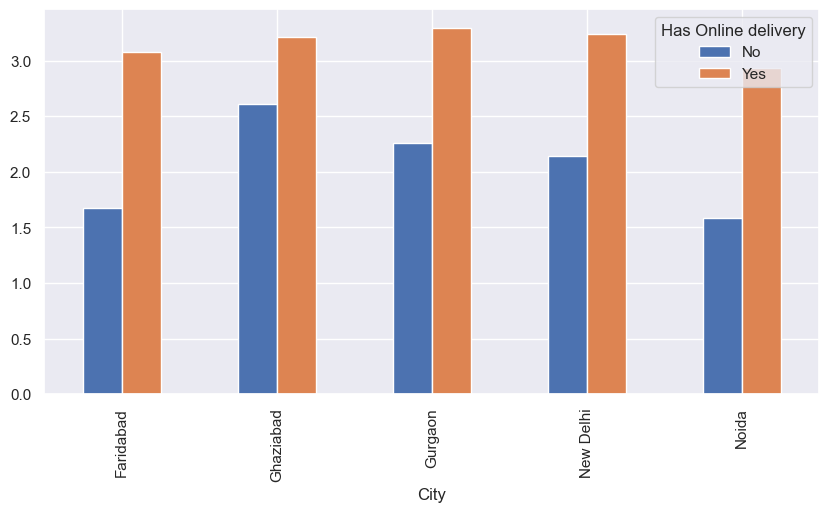

In [41]:
pivot.plot(kind = "bar" , figsize = (10,5))

## 7. Outlier Detection and missing values

In [57]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [44]:
numerical_column = df.select_dtypes(include = "number").columns
numerical_column

Index(['Restaurant ID', 'Country Code', 'Longitude', 'Latitude',
       'Average Cost for two', 'Price range', 'Aggregate rating', 'Votes'],
      dtype='object')

<Axes: ylabel='Votes'>

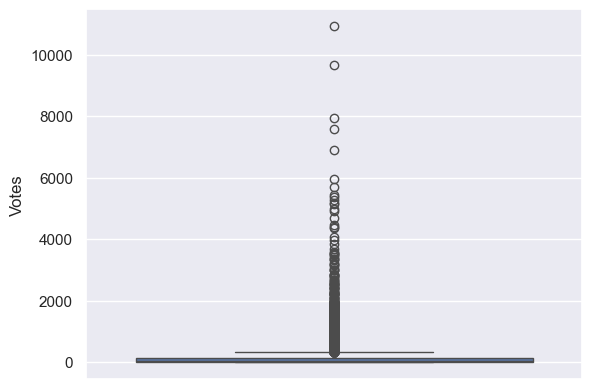

In [56]:
sns.boxplot(df["Votes"] , label = "Votes")

In [67]:
Q1 = df["Votes"].quantile(0.25)
Q3 = df["Votes"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR
outliers = df[(df["Votes"] > upper_limit) | (df["Votes"] < lower_limit)]
print(f"Number of outliers in Votes : {len(outliers)}")
print(f"Upper limit : {upper_limit}")
print(f"Lower limit : {lower_limit}")

Number of outliers in Votes : 1126
Upper limit : 320.0
Lower limit : -184.0


In [68]:
Q1 = df["Average Cost for two"].quantile(0.25)
Q3 = df["Average Cost for two"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR
outliers = df[(df["Average Cost for two"] > upper_limit) | (df["Average Cost for two"] < lower_limit)]
print(f"Number of outliers in Average Cost for two : {len(outliers)}")
print(f"Upper limit : {upper_limit}")
print(f"Lower limit : {lower_limit}")

Number of outliers in Average Cost for two : 853
Upper limit : 1375.0
Lower limit : -425.0


In [73]:
Q1 = df["Aggregate rating"].quantile(0.25)
Q3 = df["Aggregate rating"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR
outliers = df[(df["Aggregate rating"] > upper_limit) | (df["Aggregate rating"] < lower_limit)]
print(f"Number of outliers in Aggregate Rating : {len(outliers)}")
print(f"Upper limit : {upper_limit}")
print(f"Lower limit : {lower_limit}")

Number of outliers in Aggregate Rating : 2148
Upper limit : 5.5
Lower limit : 0.6999999999999997


In [79]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

## 8. Feature Relationship

##### Which  cuisins have highest customer ratings , while making sure we have enough restaurents in each cuisins to trust the comparison.

In [124]:
cuisines_rating = (
    df[df['Aggregate rating'] > 0]
    .groupby("Cuisines")['Aggregate rating']
    .agg(['mean', 'count'])
    .query("count >= 20")
    .sort_values("mean", ascending=False)
    .head(10)
)

cuisines_rating

,mean,count
Cuisines,,
Italian,3.950000,50
American,3.920690,29
Mexican,3.850000,34
"Italian, Pizza",3.795652,23
Continental,3.745000,20
Desserts,3.597500,40
"Desserts, Ice Cream",3.570833,24
"Chinese, Thai",3.516667,48
"North Indian, Continental",3.515385,26


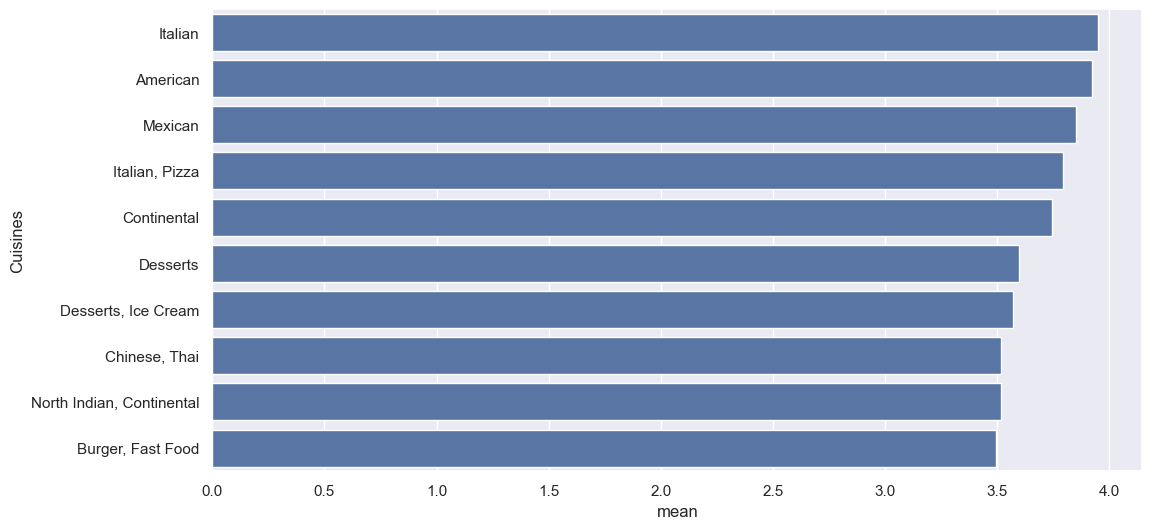

<Figure size 1200x600 with 0 Axes>

In [141]:
sns.barplot(y=cuisines_rating.head(10).index, x=cuisines_rating['mean'])
plt.show()
plt.tight_layout()

In [163]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

In [186]:
city_price_rating = df[df["Aggregate rating"] > 0 ].groupby(["Price range" , "Has Online delivery"])["Aggregate rating"].mean().unstack()
city_price_rating

Has Online delivery,No,Yes
Price range,,
1,3.231870,3.261574
2,3.414325,3.333414
3,3.833195,3.645477
4,3.886973,3.930189


<Axes: xlabel='Price range'>

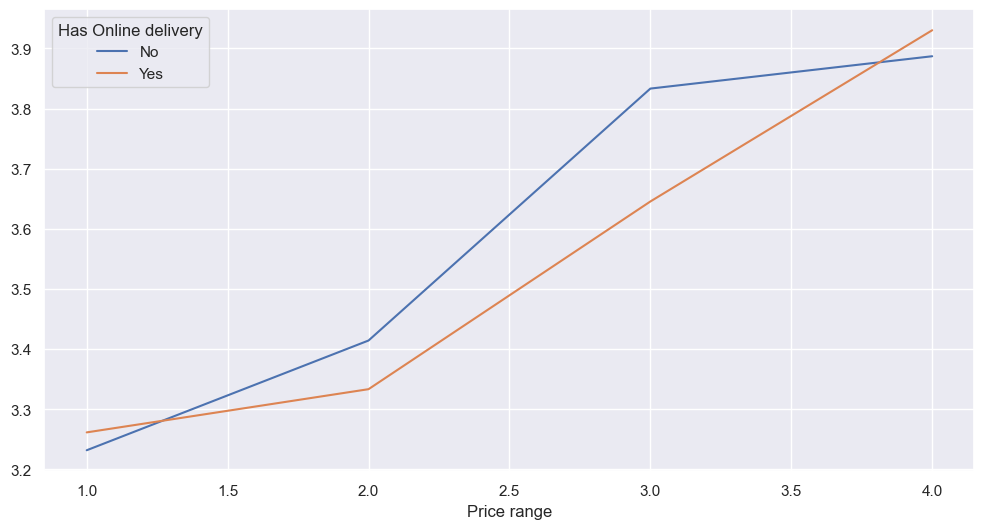

In [187]:
city_price_rating.plot(kind = "line")

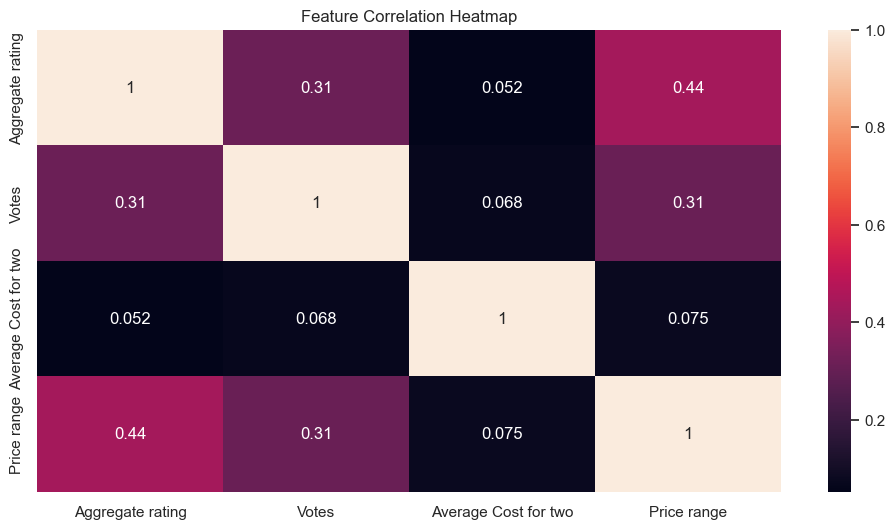

In [188]:
# Correlation Heatmap

# Select numerical columns
columns = [
    "Aggregate rating",
    "Votes",
    "Average Cost for two",
    "Price range"
]

# Calculate correlation
correlation = df[columns].corr()

# Create heatmap
sns.heatmap(
    correlation,
    annot=True
)

plt.title("Feature Correlation Heatmap")

plt.show()

---
## 9. Drawing Insights & Business Conclusions
Let's convert all our observations into real business insights.

In [189]:
# KPI Summary

# Total number of restaurants
total_restaurants = len(df)

# Average rating
rated = df[df["Aggregate rating"] > 0]

average_rating = rated["Aggregate rating"].mean()

# Percentage of restaurants with online delivery
online_delivery = (
    df["Has Online delivery"] == "Yes"
).mean() * 100

# Percentage of restaurants with table booking
table_booking = (
    df["Has Table booking"] == "Yes"
).mean() * 100

# Find the city with the most restaurants
city_counts = df["City"].value_counts()

top_city = city_counts.index[0]
top_city_count = city_counts.iloc[0]

# Display the results
print("KPI Summary")
print("-" * 30)

print("Total Restaurants:", total_restaurants)
print("Average Rating:", round(average_rating, 2))
print("Online Delivery:", round(online_delivery, 1), "%")
print("Table Booking:", round(table_booking, 1), "%")
print("Top City:", top_city)
print("Restaurants in Top City:", top_city_count)

KPI Summary
------------------------------
Total Restaurants: 9551
Average Rating: 3.44
Online Delivery: 25.7 %
Table Booking: 12.1 %
Top City: New Delhi
Restaurants in Top City: 5473


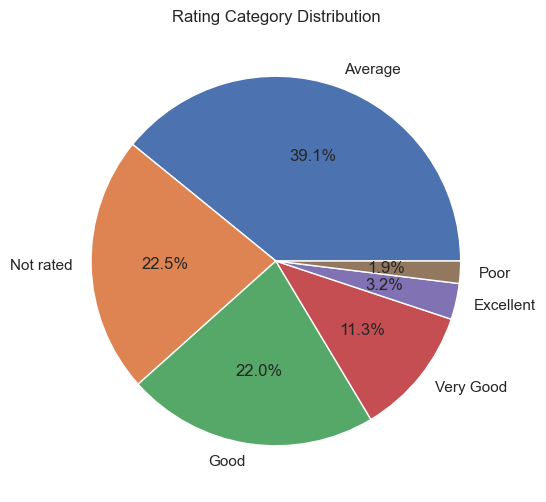

In [190]:
# Rating Category Distribution

rating_counts = df["Rating text"].value_counts()

rating_counts.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Rating Category Distribution")
plt.ylabel("")

plt.show()

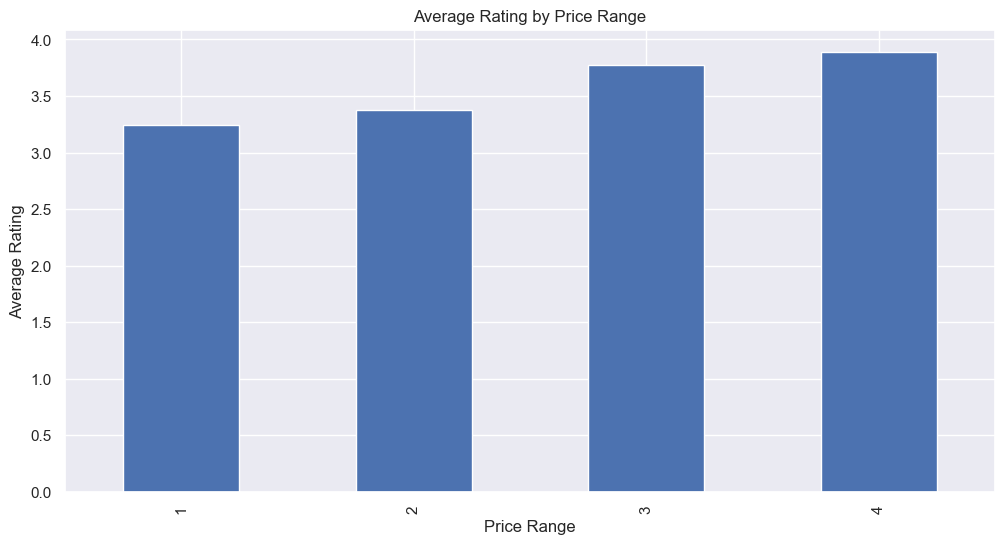

In [191]:
# Average Rating by Price Range

rated = df[df["Aggregate rating"] > 0]

average_rating = rated.groupby(
    "Price range"
)["Aggregate rating"].mean()

average_rating.plot(kind="bar")

plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")

plt.show()

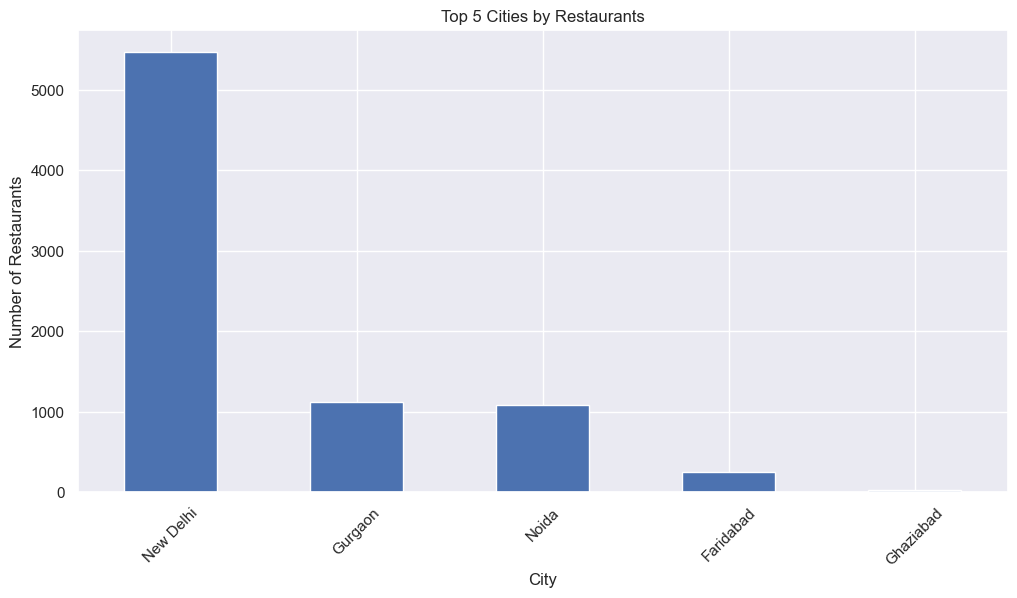

In [192]:
# Top 5 Cities

top_cities = df["City"].value_counts().head(5)

top_cities.plot(kind="bar")

plt.title("Top 5 Cities by Restaurants")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")

plt.xticks(rotation=45)

plt.show()

## 📋 Final Recommendations — Zomato EDA

### 1. Fix the Ratings Gap
**22.49%** of restaurants are "Not Rated." Zomato should send push notifications or offer incentives to encourage customers to leave ratings — this would improve both visibility and trust.

### 2. Promote Online Delivery
Only **25.66%** of restaurants offer online delivery, but their average rating (**3.25**) is noticeably better than restaurants without delivery (**2.47**). Onboarding non-delivery restaurants represents a high-impact opportunity for Zomato.

### 3. Table Booking Feature Is Underused
Only **12.12%** of restaurants offer table booking, and those that do have a better average rating (**3.44** vs **2.56** without booking). Zomato should promote this feature more widely, especially in the fine-dining segment.

### 4. Premium Restaurants Perform Better
Price range 4 (most expensive) has an average rating of **3.89**, compared to just **3.24** for price range 1 (cheapest). However, the correlation between cost and rating is weak (**0.08**) — meaning **being expensive alone doesn't guarantee a good rating**; quality and service matter more.

### 5. Votes Are a Trust Signal
The correlation between votes and rating is **0.41** — the more engagement a restaurant gets, the more stable/higher its rating tends to be. New restaurants should focus on collecting early reviews.

### 6. Winning Cuisines
**Italian (3.95)**, **American (3.92)**, and **Mexican (3.85)** are the top-rated cuisines (among those with at least 20 restaurants). Meanwhile, North Indian is the most common cuisine (936 restaurants) but its average rating isn't as high — a sign of **market saturation**, meaning differentiation is key.

### 7. Market Concentration Risk
Just 3 cities — **New Delhi, Gurgaon, and Noida** — account for over **77%** of all restaurants. Expansion strategy should focus on tier-2 cities where competition is lower.

### 8. Data Quality Note
The currency data shows this is a **multi-country dataset** (beyond India — includes US, UK, UAE, Brazil, etc.). If the analysis should be India-specific, filtering by `Currency = "Indian Rupees(Rs.)"` would ensure cost/rating comparisons are apples-to-apples.

---
## 10. End-to-End EDA Summary

### What We Did — Full EDA Workflow

| Phase | Task | Finding |
|-------|------|---------|
| 1 | Understood EDA objectives | Defined key business questions |
| 2 | Dataset inspection | 9,551 rows × 21 columns, mixed types |
| 3 | Data quality | 9 missing Cuisines, 0 duplicates |
| 4 | Univariate analysis | 22% Not Rated, 46% restaurants are cheap |
| 5 | Bivariate analysis | Price & Table booking correlate with rating |
| 6 | Multivariate analysis | New Delhi dominates across all metrics |
| 7 | Outlier analysis | Extreme votes are real signals (not errors) |
| 8 | Pattern discovery | Higher cost → better rating (linear trend) |
| 9 | Business conclusions | 4 actionable recommendations derived |
| 10 | Dataset ready | Clean data ready for ML or dashboard |